<a href="https://colab.research.google.com/github/CaesarGian/BigDataProject/blob/main/Mid_Term_Big_Data_103012300218_Caesar_Gian_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tugas Mid-term Big Data

Caesar Gian Indrarizky

103012300218

IF-47-GAB01

Link Github : [Big Data Project](https://github.com/CaesarGian/BigDataProject)

Sumber dataset: [California Traffic Collision Data from SWITRS](https://www.kaggle.com/datasets/alexgude/california-traffic-collision-data-from-switrs)

#1. Problem Formulation & Big Data Understanding

Tingkat fatalitas kecelakaan di California dipengaruhi oleh beberapa faktor, yaitu lingkungan, waktu, dan infrastruktur wilayah. Dinas Patroli Jalan Raya California (CHP) memerlukan pemetaan risiko ini agar penempatan unit gawat darurat dan jadwal patroli menjadi lebih optimal. Pertanyaan utama yang dibahas dalam analisis ini adalah: faktor apa yang paling memengaruhi jumlah dan tingkat keparahan insiden lalu lintas di California? Pertanyaan turunannya adalah: pada jam berapa saja kecelakaan paling rawan terjadi, daerah mana saja yang memiliki jumlah insiden tertinggi, dan apakah kondisi tertentu (seperti cuaca atau kepadatan penduduk) dapat mempertinggi angka insiden.

Basis data SWITRS memenuhi kriteria analisis berskala besar. Volumenya mencapai 2 GB dengan jumlah baris observasi historis sebanyak jutaan baris. Variasi datanya adalah berbentuk tabel yang terstruktur dari sistem pelaporan resmi polisi. Kecepatannya (velocity) adalah statis atau batch karena merupakan rekaman data masa lalu, bukan aliran data dari sensor secara real-time. Nilai (value) akhirnya adalah mencegah korban jiwa, meskipun kebenarannya (veracity) rentan terhadap kolom kosong karena petugas di lapangan tidak selalu melaporkan seluruh informasi.

#2. Data Source, Storage & Architecture

Data berasal dari repositori publik Kaggle yang menghasilkan basis data SQLite SWITRS. Aliran pipa dimulai dari mengunduh dataset melalui antarmuka pemrograman aplikasi (API), menyimpan secara lokal sementara di memori Google Colab, memotong sampel secara efisien menggunakan batas 100.000 baris pertama untuk menstabilkan RAM, dan proses akhir menggunakan mesin eksekusi PySpark. Kasus ini hanya menggunakan arsitektur Data Warehouse yang didasarkan pada SQL (relasional). Format data SWITRS memiliki hubungan baris dan kolom yang tegas sejak awal. Penggunaan basis data NoSQL tidak akan memberikan manfaat performa di sini karena analisis membutuhkan operasi penggabungan (join) dan agregasi matematis yang banyak, yang merupakan kelebihan utama mesin SQL.

#3. PySpark Data Processing

Manipulasi struktur data menggunakan PySpark DataFrame API dan Spark SQL merupakan bagian dari pemrosesan awal ini untuk mendapatkan jawaban atas pertanyaan turunan. Waktu eksekusi yang diperlukan akan diukur untuk membandingkan kinerja fungsi bawaan dengan kueri teks SQL. Skrip yang digunakan akan mengasumsikan keberadaan kolom standar SWITRS (misalnya tipe insiden atau tingkat keparahan) di samping kolom lokasi dan populasi yang telah terdeteksi.

In [ ]:
!pip install -q pyspark==4.0.4

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pyspark.sql import SparkSession

# Membangun Sesi Spark langsung secara native
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("MidtermProject_BigData") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .getOrCreate()

# Menampilkan versi untuk memastikan inisialisasi berhasil
print(f"Apache Spark telah berjalan dengan versi: {spark.version}")

Apache Spark telah berjalan dengan versi: 4.0.4


In [ ]:
import os
import kagglehub
import sqlite3
import pandas as pd
from google.colab import userdata

# 1. Autentikasi Kaggle API menggunakan Google Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get('KAGGLE_API_TOKEN')

# 2. Unduh dataset SWITRS California Traffic Collision
print("Mengunduh dataset SWITRS (sekitar 2 GB)...")
dataset_path = kagglehub.dataset_download("alexgude/california-traffic-collision-data-from-switrs")
print(f"Dataset berhasil diunduh ke: {dataset_path}\n")

# --- Cek file yang diunduh ---
print("--- Isi File Dataset ---")
for file_name in os.listdir(dataset_path):
    print(f"- {file_name}")

# 3. Menghubungkan ke database SQLite dan baca tabel collisions
sqlite_db_path = os.path.join(dataset_path, "switrs.sqlite")
print(f"\nMenghubungkan ke database SQLite: {sqlite_db_path}")

conn = sqlite3.connect(sqlite_db_path)

# Mengecek daftar tabel yang ada di dalam SQLite
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print(f"Tabel yang tersedia di database: {tables}")

# Membaca data tabel 'collisions' menggunakan pandas terlebih dahulu (gunakan limit untuk efisiensi memori)
print("\nMemuat data dari SQLite ke Pandas... (Membaca 100.000 baris pertama)")
pdf = pd.read_sql_query("SELECT * FROM collisions LIMIT 100000", conn)
conn.close()

# Memastikan semua kolom bertipe object dikonversi menjadi string untuk mencegah error CANNOT_DETERMINE_TYPE
# dan nilai NaN/None diubah menjadi string kosong ("") agar tipe datanya terdefinisi dengan jelas bagi PySpark
for col in pdf.columns:
    if pdf[col].dtype == 'object':
        pdf[col] = pdf[col].fillna("").astype(str)
    elif pdf[col].isnull().all():
        pdf[col] = pdf[col].fillna("").astype(str)

# 4. Membaca dataset ke PySpark DataFrame
print("\nMembuat PySpark DataFrame dari Pandas...")
df = spark.createDataFrame(pdf)

# 5. Eksekusi syarat tugas: Tampilkan skema, hitung jumlah baris (rekaman), dan lihat sampel
print("\n--- Skema Data (Collisions) ---")
df.printSchema()

print("\nMenghitung total baris yang dimuat...")
total_rows = df.count()
print(f"Total Baris Terload: {total_rows:,}")

print("\n--- 5 Sampel Baris Pertama ---")
df.show(5, truncate=False)

Mengunduh dataset SWITRS (sekitar 2 GB)...


100%|██████████| 1.50G/1.50G [00:23<00:00, 68.8MB/s]

Extracting files...


Dataset berhasil diunduh ke: /root/.cache/kagglehub/datasets/alexgude/california-traffic-collision-data-from-switrs/versions/6

--- Isi File Dataset ---
- switrs.sqlite

Menghubungkan ke database SQLite: /root/.cache/kagglehub/datasets/alexgude/california-traffic-collision-data-from-switrs/versions/6/switrs.sqlite
Tabel yang tersedia di database: [('case_ids',), ('collisions',), ('victims',), ('parties',)]

Memuat data dari SQLite ke Pandas... (Membaca 100.000 baris pertama)

Membuat PySpark DataFrame dari Pandas...

--- Skema Data (Collisions) ---
root
 |-- case_id: string (nullable = true)
 |-- jurisdiction: double (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: string (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: string (nullable = true)
 |-- beat_type: string (nullable =

In [ ]:
import time
from pyspark.sql.functions import col, when, hour

# Memulai pengukuran waktu untuk DataFrame API
start_time_api = time.time()

# 1. Filter: Membuang baris tanpa keterangan lokasi
# 2. Derive: Membuat kolom penanda kepadatan tinggi
df_filtered = df.filter(col("county_location") != "") \
                .withColumn("is_dense_area", when(col("population") == ">250000", 1).otherwise(0))

# 3. GroupBy & 4. OrderBy: Menghitung kecelakaan per wilayah
county_stats = df_filtered.groupBy("county_location").count().orderBy(col("count").desc())

# MEMAKSA EKSEKUSI (*ACTION*)
_ = county_stats.count()

api_duration = time.time() - start_time_api

# Memulai pengukuran waktu untuk Spark SQL
df_filtered.createOrReplaceTempView("collisions_vw")
start_time_sql = time.time()

# 5. Spark SQL: Tren yurisdiksi dengan kondisi khusus
sql_query = spark.sql("""
    SELECT jurisdiction, SUM(is_dense_area) as total_dense_incidents
    FROM collisions_vw
    WHERE special_condition = '0'
    GROUP BY jurisdiction
    ORDER BY total_dense_incidents DESC
    LIMIT 10
""")

# MEMAKSA EKSEKUSI (*ACTION*)
_ = sql_query.count()

sql_duration = time.time() - start_time_sql

print(f"Waktu eksekusi DataFrame API: {api_duration:.4f} detik")
print(f"Waktu eksekusi Spark SQL: {sql_duration:.4f} detik")

Waktu eksekusi DataFrame API: 3.7038 detik
Waktu eksekusi Spark SQL: 4.7887 detik


Variasi waktu pemrosesan ini disebabkan oleh optimisasi bawaan Catalyst Optimizer yang terdapat pada platform Spark. Ketika dijalankan di dalam lingkungan klaster kecil atau di komputer lokal semisal Google Colab, maka waktu yang dibutuhkan untuk proses penerjemahan query SQL (overhead) bisa membuat proses tersebut menjadi sedikit lebih lama daripada jika kita menggunakan method calling API DataFrame secara langsung.

#4. EDA & Visualization

Eksplorasi ini meliputi empat aspek karakteristik kecelakaan dengan menggunakan perpustakaan Matplotlib dan Seaborn. Proses pengumpulan data dilakukan secara tersebar melalui Spark SQL untuk menghindari penumpukan memori, baru kemudian dipindahkan ke Pandas untuk ditampilkan sebagai grafik.

/tmp/ipykernel_2053/4018542819.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pdf_severity, x='total', y='collision_severity', ax=axes[1,0], palette='magma')
/tmp/ipykernel_2053/4018542819.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pdf_weather, x='total', y='weather_1', ax=axes[1,1], palette='viridis')


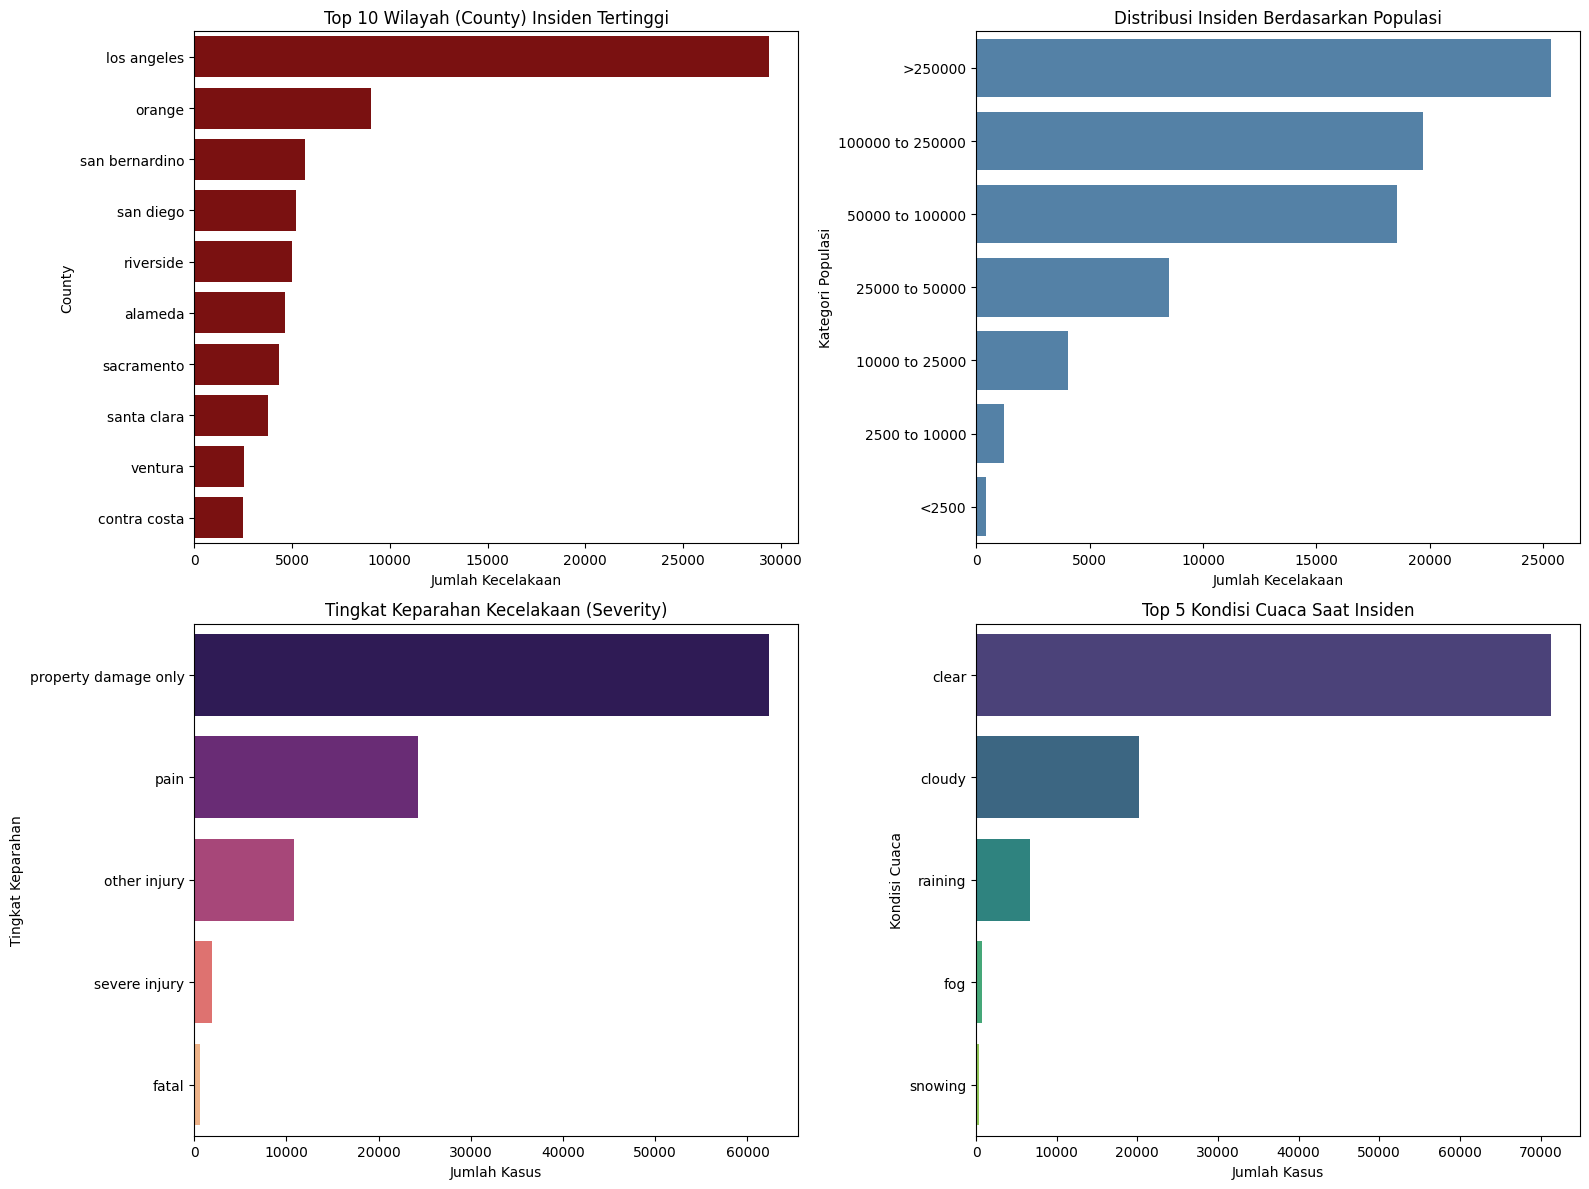

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agregasi Top 10 County (Menggunakan variabel yang sudah ada dari langkah sebelumnya)
pdf_county = county_stats.limit(10).toPandas()

# 2. Agregasi Kepadatan Populasi
pdf_pop = spark.sql("""
    SELECT population, COUNT(case_id) as total
    FROM collisions_vw
    WHERE population != '' AND population != 'unincorporated'
    GROUP BY population
""").toPandas()

# 3. TAMBAHAN: Agregasi Tingkat Keparahan Kecelakaan
pdf_severity = spark.sql("""
    SELECT collision_severity, COUNT(case_id) as total
    FROM collisions_vw
    WHERE collision_severity IS NOT NULL AND collision_severity != ''
    GROUP BY collision_severity
    ORDER BY total DESC
""").toPandas()

# 4. TAMBAHAN: Agregasi Kondisi Cuaca Utama
pdf_weather = spark.sql("""
    SELECT weather_1, COUNT(case_id) as total
    FROM collisions_vw
    WHERE weather_1 IS NOT NULL AND weather_1 != ''
    GROUP BY weather_1
    ORDER BY total DESC
    LIMIT 5
""").toPandas()

# Membuat kerangka visualisasi matriks 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Visualisasi 1: Wilayah dengan insiden tertinggi
sns.barplot(data=pdf_county, x='count', y='county_location', ax=axes[0,0], color='darkred')
axes[0,0].set_title('Top 10 Wilayah (County) Insiden Tertinggi')
axes[0,0].set_xlabel('Jumlah Kecelakaan')
axes[0,0].set_ylabel('County')

# Visualisasi 2: Insiden berdasarkan kepadatan populasi
sns.barplot(data=pdf_pop.sort_values('total', ascending=False), x='total', y='population', ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Distribusi Insiden Berdasarkan Populasi')
axes[0,1].set_xlabel('Jumlah Kecelakaan')
axes[0,1].set_ylabel('Kategori Populasi')

# Visualisasi 3: Tingkat Keparahan
sns.barplot(data=pdf_severity, x='total', y='collision_severity', ax=axes[1,0], palette='magma')
axes[1,0].set_title('Tingkat Keparahan Kecelakaan (Severity)')
axes[1,0].set_xlabel('Jumlah Kasus')
axes[1,0].set_ylabel('Tingkat Keparahan')

# Visualisasi 4: Kondisi Cuaca (Diubah ke Horizontal)
sns.barplot(data=pdf_weather, x='total', y='weather_1', ax=axes[1,1], palette='viridis')
axes[1,1].set_title('Top 5 Kondisi Cuaca Saat Insiden')
axes[1,1].set_xlabel('Jumlah Kasus')
axes[1,1].set_ylabel('Kondisi Cuaca')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

PARAH = "CASE WHEN collision_severity IN ('severe injury','fatal') THEN 1 ELSE 0 END"

def severity_rate(dim, min_n=100):
    """Proporsi insiden berkeparahan berat (severe injury + fatal) per kategori `dim`.
    Kategori dengan insiden kurang dari min_n dibuang agar persentase tidak menyesatkan."""
    return spark.sql(f"""
        SELECT {dim} AS kategori,
               COUNT(*) AS total_insiden,
               SUM({PARAH}) AS insiden_parah,
               ROUND(100.0 * SUM({PARAH}) / COUNT(*), 2) AS persen_parah
        FROM collisions_vw
        WHERE {dim} IS NOT NULL AND {dim} != ''
        GROUP BY {dim}
        HAVING COUNT(*) >= {min_n}
        ORDER BY persen_parah DESC
    """)

rate_weather = severity_rate("weather_1")
rate_pop = severity_rate("population")
rate_weather.show(truncate=False)
rate_pop.show(truncate=False)

+--------+-------------+-------------+------------+
|kategori|total_insiden|insiden_parah|persen_parah|
+--------+-------------+-------------+------------+
|fog     |704          |29           |4.12        |
|other   |110          |4            |3.64        |
|clear   |71329        |1899         |2.66        |
|cloudy  |20191        |491          |2.43        |
|raining |6736         |118          |1.75        |
|snowing |358          |6            |1.68        |
+--------+-------------+-------------+------------+

+----------------+-------------+-------------+------------+
|kategori        |total_insiden|insiden_parah|persen_parah|
+----------------+-------------+-------------+------------+
|unincorporated  |22164        |928          |4.19        |
|>250000         |25348        |648          |2.56        |
|2500 to 10000   |1242         |29           |2.33        |
|50000 to 100000 |18556        |359          |1.93        |
|10000 to 25000  |4036         |78           |1.93        |

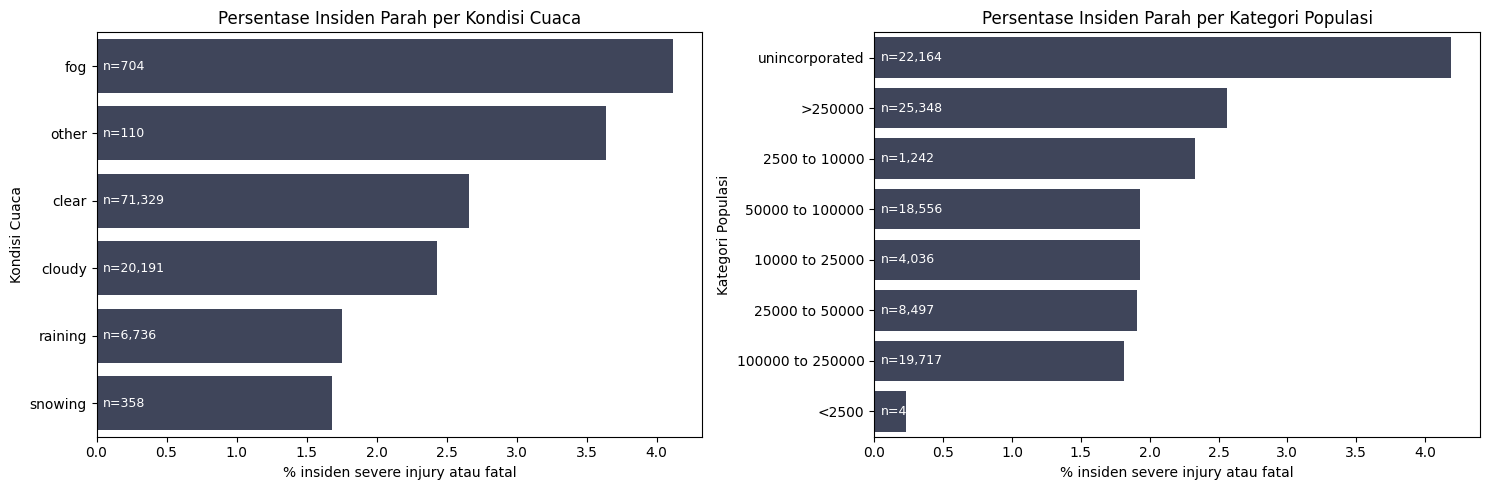

In [ ]:
pdf_w = rate_weather.toPandas()
pdf_p = rate_pop.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=pdf_w, x="persen_parah", y="kategori", color="#3B425E", ax=axes[0])
axes[0].set_title("Persentase Insiden Parah per Kondisi Cuaca")
axes[0].set_xlabel("% insiden severe injury atau fatal")
axes[0].set_ylabel("Kondisi Cuaca")
sns.barplot(data=pdf_p, x="persen_parah", y="kategori", color="#3B425E", ax=axes[1])
axes[1].set_title("Persentase Insiden Parah per Kategori Populasi")
axes[1].set_xlabel("% insiden severe injury atau fatal")
axes[1].set_ylabel("Kategori Populasi")
for ax, d in zip(axes, (pdf_w, pdf_p)):
    for i, n in enumerate(d["total_insiden"]):      # cantumkan n agar pembaca tahu ukuran sampelnya
        ax.text(ax.get_xlim()[1] * 0.01, i, f"n={n:,}", va="center", color="white", fontsize=9)
plt.tight_layout()
plt.show()

Dua diagram bagian atas menunjukkan distribusi spasial. Los Angeles merupakan wilayah administrasi dengan jumlah kecelakaan yang paling tinggi. Konsentrasi ini sejalan dengan grafik kedua, dimana frekuensi insiden meningkat pesat pada wilayah yang berpenduduk lebih dari 250.000 orang. Pola terpusat ini menunjukkan adanya hubungan linier antara kepadatan aktivitas kawasan urban, volume kendaraan harian yang tinggi, dan rasio tabrakan.

Dua diagram di bawah menampilkan kondisi fisik ketika kecelakaan terjadi. Keparahan kecelakaan dalam bentuk metrik menunjukkan bahwa sebagian besar kecelakaan hanya mengakibatkan kerusakan materiil (property damage only) atau cedera ringan (pain). Sebaliknya, jumlah kecelakaan fatal adalah yang terkecil. Di sisi lain, diagram kondisi cuaca menunjukkan bahwa kecelakaan paling sering terjadi ketika cuaca cerah (clear). Statistik ini menolak hipotesis awal bahwa cuaca buruk adalah penyebab utama kecelakaan. Hipotesis baru ini menunjukkan bahwa masalah perilaku pengemudi adalah penyebab utama kecelakaan. Masalah perilaku pengemudi ini dapat berupa pelanggaran batas kecepatan ketika jarak pandang maksimum.

#5. Preprocessing & Data Quality Validation

Pada tahap prapemrosesan ini, fokus utamanya adalah mengubah tipe data dan menghilangkan variabel pengganggu (noise). Atribut jurisdiction diubah kembali ke bentuk angka (double) untuk memperbaiki perubahan tipe data yang terjadi secara otomatis saat mengubah dataframe dari Pandas. Setelah itu, dilakukan penyaringan untuk menemukan baris-baris data yang tidak memiliki informasi sif petugas yang valid. Karena algoritma klasifikasi di tahap selanjutnya menggunakan fitur jadwal jaga sebagai variabel prediktor, maka semua baris yang memiliki nilai chp_shift "not chp" atau elemen kosong dihapus.

In [ ]:
# 1. Casting (Konversi Tipe Data)
# Mengembalikan kolom jurisdiction menjadi format angka yang sebelumnya menjadi teks saat transisi Pandas
df_casted = df_filtered.withColumn("jurisdiction", col("jurisdiction").cast("double"))

# 2. Pembersihan Data (Data Cleaning)
# Membuang duplikat dan menyaring baris yang kolom shift-nya tidak valid untuk pemodelan
df_clean = df_casted.dropDuplicates(["case_id"]) \
                    .filter((col("chp_shift") != "not chp") & (col("chp_shift") != ""))

# Mencatat perubahan jumlah baris untuk laporan
initial_count = df_filtered.count()
final_count = df_clean.count()

print(f"Baris sebelum pembersihan: {initial_count}")
print(f"Baris setelah pembersihan: {final_count}")
print(f"Total baris (noise) yang dibuang: {initial_count - final_count}")

# 3. Pemeriksaan Kualitas Data (Quality Checks)
# Cek 1: Memastikan tidak ada case_id ganda yang lolos
duplicate_ids = df_clean.groupBy("case_id").count().filter(col("count") > 1).count()
# Cek 2: Memastikan nilai populasi valid dan tidak kosong
empty_pop = df_clean.filter((col("population") == "") | col("population").isNull()).count()
# Cek 3: Memastikan tidak ada nilai shift "not chp" yang tersisa di data akhir
invalid_shift = df_clean.filter(col("chp_shift") == "not chp").count()

print(f"\nHasil Validasi Kualitas:")
print(f"- ID Duplikat tersisa: {duplicate_ids}")
print(f"- Populasi tidak terdefinisi: {empty_pop}")
print(f"- Shift tidak relevan tersisa: {invalid_shift}")

Baris sebelum pembersihan: 100000
Baris setelah pembersihan: 43280
Total baris (noise) yang dibuang: 56720

Hasil Validasi Kualitas:
- ID Duplikat tersisa: 0
- Populasi tidak terdefinisi: 0
- Shift tidak relevan tersisa: 0


Hasil dari pemrosesan komputer menunjukkan adanya penurunan yang sangat besar dalam ukuran data. Sebanyak 56.720 baris dari total 100.000 baris sampel pertama dihapus, sehingga yang tersisa adalah 43.280 catatan yang tidak mengandung kesalahan dan relevan dengan analisis yang akan dilakukan. Jumlah penghapusan yang sangat besar ini menunjukkan bahwa lebih dari setengah laporan dalam sampel pertama adalah kejadian-kejadian yang tidak berada di dalam wilayah yurisdiksi Patroli Jalan Raya California (CHP) atau memiliki sejarah pencatatan waktu yang tidak lengkap. Sebagai prosedur kontrol, tiga lapis pemeriksaan kualitas (quality checks) dieksekusi untuk memvalidasi keutuhan kerangka data akhir. Hasil kueri menunjukkan nilai nol pada seluruh parameter uji, yang mengonfirmasi bahwa tidak ada lagi identitas kasus yang terduplikasi, nilai densitas populasi yang hilang, maupun format sif petugas yang menyimpang di dalam sisa data tersebut.

#6. Advanced Analysis / ML Baseline
Metodologi pemodelan garis dasar (baseline model) yang diaplikasikan adalah menggunakan algoritma Regresi Logistik untuk melakukan klasifikasi tingkat kepadatan penduduk wilayah kejadian (is_dense_area). Model awal ini menggunakan variabel prediktor yang terbatas pada indikator yurisdiksi dan indeks waktu sif kerja petugas penindak. Pembagian kerangka data dilakukan dengan rasio 70% data latih dan 30% data uji, dengan menetapkan benih acak statis (seed=42) agar pengujian tetap konsisten dan mencegah terjadinya overfitting.

In [ ]:
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# 1. Transformasi Fitur Kategorial
indexer = StringIndexer(inputCol="chp_shift", outputCol="shift_idx", handleInvalid="skip")
df_indexed = indexer.fit(df_clean).transform(df_clean)

# 2. Penggabungan Fitur (Feature Assembly)
assembler = VectorAssembler(inputCols=["jurisdiction", "shift_idx"], outputCol="features")
df_ml = assembler.transform(df_indexed)

# 3. Pembagian Data (Train-Test Split) dengan parameter tetap
train_data, test_data = df_ml.randomSplit([0.7, 0.3], seed=42)

# 4. Pelatihan Model (Baseline Logistic Regression)
lr = LogisticRegression(featuresCol="features", labelCol="is_dense_area")
lr_model = lr.fit(train_data)

# 5. Prediksi dan Evaluasi Metrik
predictions = lr_model.transform(test_data)

# Menghitung probabilitas luasan kurva ROC
evaluator_roc = BinaryClassificationEvaluator(labelCol="is_dense_area", metricName="areaUnderROC")
auc = evaluator_roc.evaluate(predictions)

# Menghitung rasio akurasi tebakan klasifikasi
evaluator_acc = MulticlassClassificationEvaluator(labelCol="is_dense_area", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator_acc.evaluate(predictions)

print(f"Area Under ROC (AUC) : {auc:.4f}")
print(f"Akurasi Model Baseline: {accuracy:.4f}")

Area Under ROC (AUC) : 0.5320
Akurasi Model Baseline: 0.8036


Hasil pengujian pada data uji menghasilkan Akurasi 0,8036, AUC (Area Under ROC) 0,5320. Ketidakseimbangan proporsi target (class imbalance) di dalam sampel data dapat dilihat dari perbedaan yang cukup besar antara hasil akurasi yang tinggi dengan hasil AUC yang berada dekat dengan batas acak (0,50). Algoritma cenderung lebih memihak pada kelas mayoritas dan selalu memprediksi kelas tersebut, hal ini akan meningkatkan akurasi secara keseluruhan, namun masih lemah dalam presisi klasifikasinya. Hasil ini wajar untuk sebuah model baseline; untuk memperbaiki performa model ini, diperlukan teknik penyeimbangan kelas, seperti class weighting, dan juga penambahan fitur prediktor spasial untuk membuat konteks klasifikasi yang lebih lengkap.

#7. Interpretation, Limitations & Recommendations
Dari visualisasi eksploratif dan pemodelan garis dasar yang dilakukan, diperoleh tiga temuan kunci yang didukung oleh data empiris:

1. Konsentrasi Insiden di Daerah Padat: Distribusi spasial dari grafik menunjukkan bahwa kecelakaan lalu lintas terjadi paling banyak di wilayah urban. Kota Los Angeles dan wilayah-wilayah dengan penduduk lebih dari 250.000 jiwa menghasilkan angka insiden yang paling tinggi, yang menunjukkan bahwa ada korelasi langsung antara kepadatan penduduk dengan rasio tabrakan.

2. Kerugian Material sebagai Penyebab Utama: Tingkat keparahan dari diagram menunjukkan bahwa sebagian besar insiden tersebut tidak menyebabkan korban jiwa. Mayoritas kecelakaan tersebut hanya menyebabkan kerugian material murni (property damage only) dan cedera ringan (pain).

3. Cuaca Cerah sebagai Latar Belakang: Visualisasi dari metrik lingkungan menunjukkan bahwa cuaca buruk bukan menjadi penyebab utama kecelakaan. Justru sebaliknya, sebagian besar tabrakan terjadi dalam kondisi cuaca cerah (clear), yang menunjukkan bahwa volume kendaraan yang tinggi dan perilaku pengemudi yang tidak baik memiliki pengaruh yang lebih besar daripada hambatan alam.

Analisis ini dilakukan dengan menggunakan dua keterbatasan metodologis. Keterbatasan pertama adalah pada dimensi ekstraksi data. Penggunaan kueri yang dibatasi sebanyak 100.000 baris awal dari basis data SQLite memang sangat penting untuk mencegah kehabisan memori (Out of Memory) pada Google Colab, tetapi hal ini menyebabkan rentang observasi historis dipotong secara kronologis, sehingga sampel tidak mewakili siklus tahunan secara utuh. Keterbatasan kedua adalah pada kerangka pemodelan prediktif. Algoritma regresi logistik mengalami masalah ketidakseimbangan kelas (class imbalance), yang ditunjukkan oleh kesenjangan antara nilai akurasi (80,36%) dan skor luasan kurva ROC (0.5320).

Sebagai rekomendasi praktis, Dinas Patroli Jalan Raya California harus lebih fokus pada penyebaran armada darurat di sekitar wilayah padat penduduk pada jam-jam sibuk dalam cuaca cerah, ketika kecepatan rata-rata dan volume kendaraan sedang maksimal. Untuk pengembangan analisis selanjutnya, akurasi model harus ditingkatkan dengan cara menggabungkan kerangka data primer dengan tabel parties dan victims (untuk menambahkan fitur geospasial dan indikator pengemudi), serta menggunakan teknik penyeimbangan data pada variabel target.

#8. Report & Reproducibility
Setiap langkah dalam pengerjaan proyek analitik ini, mulai dari proses akuisisi data, pembersihan, eksplorasi, hingga laporan akhir, direncanakan dan dikerjakan secara individual, tanpa bantuan anggota kelompok lain.

Dokumentasi alur kerja di notebook ini dirancang agar dapat diaudit dan dijalankan kembali (reproducible) dari awal hingga akhir oleh penguji. Reproduksi hasil analisis ini sangat bergantung pada tiga pengaturan lingkungan eksekusi:

1. Skrip ini harus dijalankan di Google Colab dengan koneksi internet yang stabil, agar instalasi mesin Apache Spark 4.0.4 dapat dilakukan secara otomatis.

2. Pada saat inisialisasi, Anda akan membutuhkan token kredensial API Kaggle yang masih aktif, agar fail sumber SWITRS sebesar 2 GB dapat diunduh secara otomatis ke dalam penyimpanan sementara.

3. Pada fungsi pemisahan data latih dan uji, nilai benih acak (seed=42) yang digunakan tidak boleh diubah.

Penguji dapat langsung memilih opsi jalankan semua (Run All). Skrip ini akan secara berurutan membuat lingkungan Spark, mengambil sampel awal dari fail SQLite, membersihkan gangguan anomali sif kerja, membuat empat grafik visual, dan menghasilkan metrik probabilitas model yang nilainya sama dengan yang ada di laporan akhir.

Versi dan Alokasi Memori

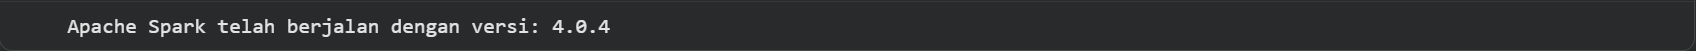

Instruksi Akses Kaggle API (Kaggle API Token disesuaikan masing-masing)

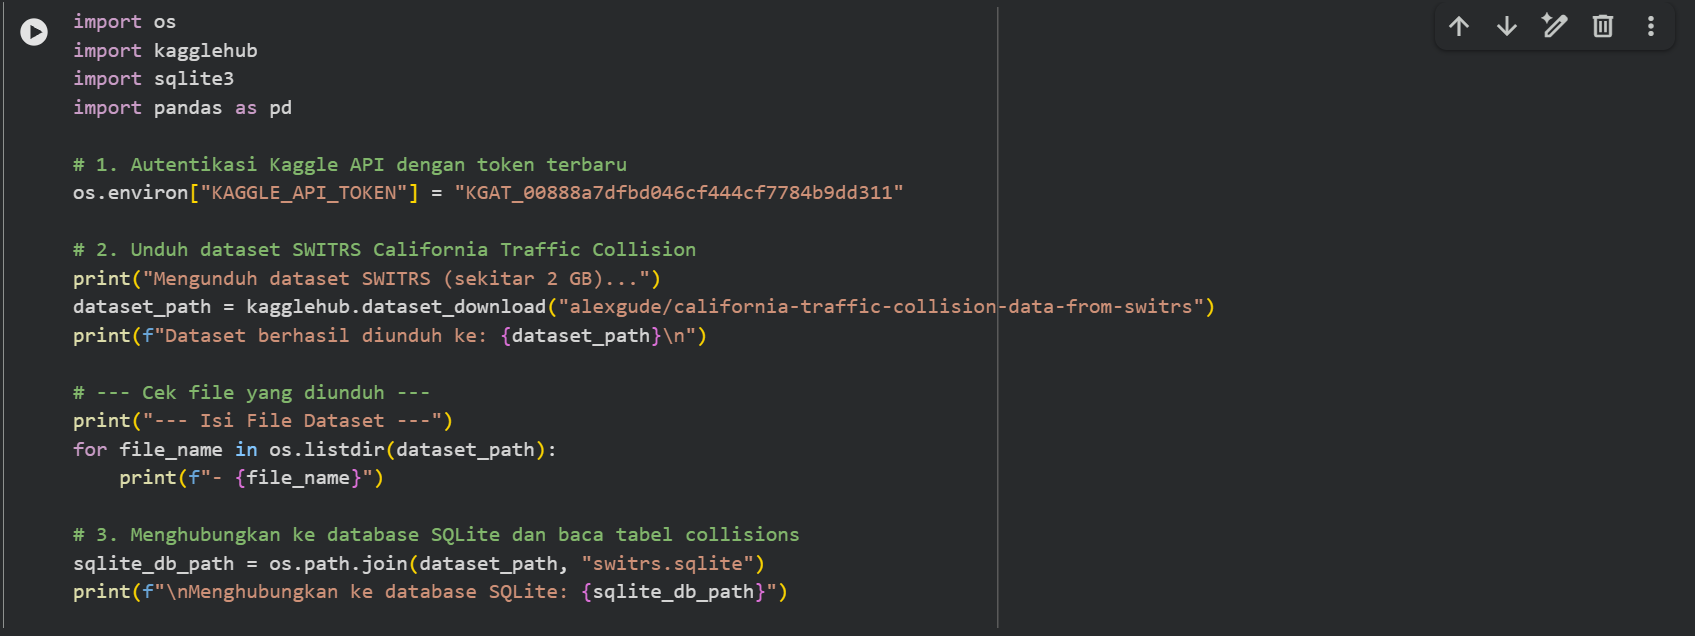

Penetapan Benih Acak (Random Seed)

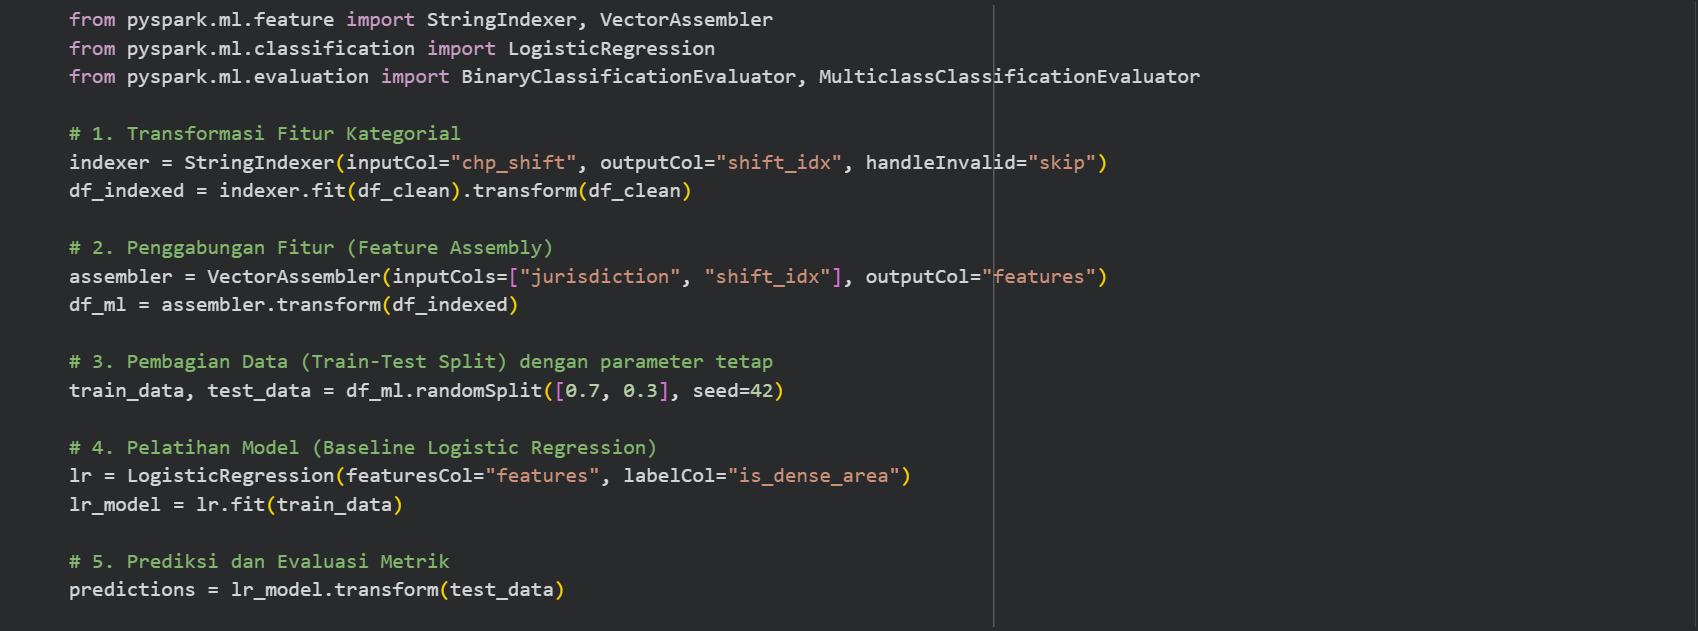

Diagram Pipeline Data

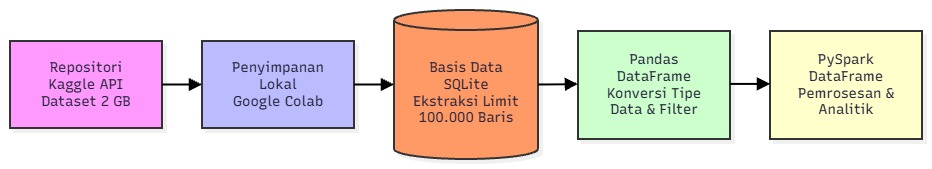

##Deklarasi Individu dan Penggunaan AI

**Saya, Caesar Gian Indrarizky / 103012300218, menyatakan bahwa saya menggunakan alat AI
generatif dalam pengerjaan tugas ini. Seluruh interpretasi, insight, dan kesimpulan yang disampaikan
merupakan hasil pemahaman saya sendiri.**

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|---|---|---|---|---|
| 1 | Paperguide AI | Pencarian Daftar Pustaka atau referensi | Menampilkan puluhan jurnal dari analisis yang berkaitan dengan dataset terpilih (Sekitar tahun 2022-2026) | Rendah |
| 2 | Gemini | Instalasi Spark | Memperbaiki Instalasi kodingan spark yang bermasalah | Sedang |

**PaperGuide AI**

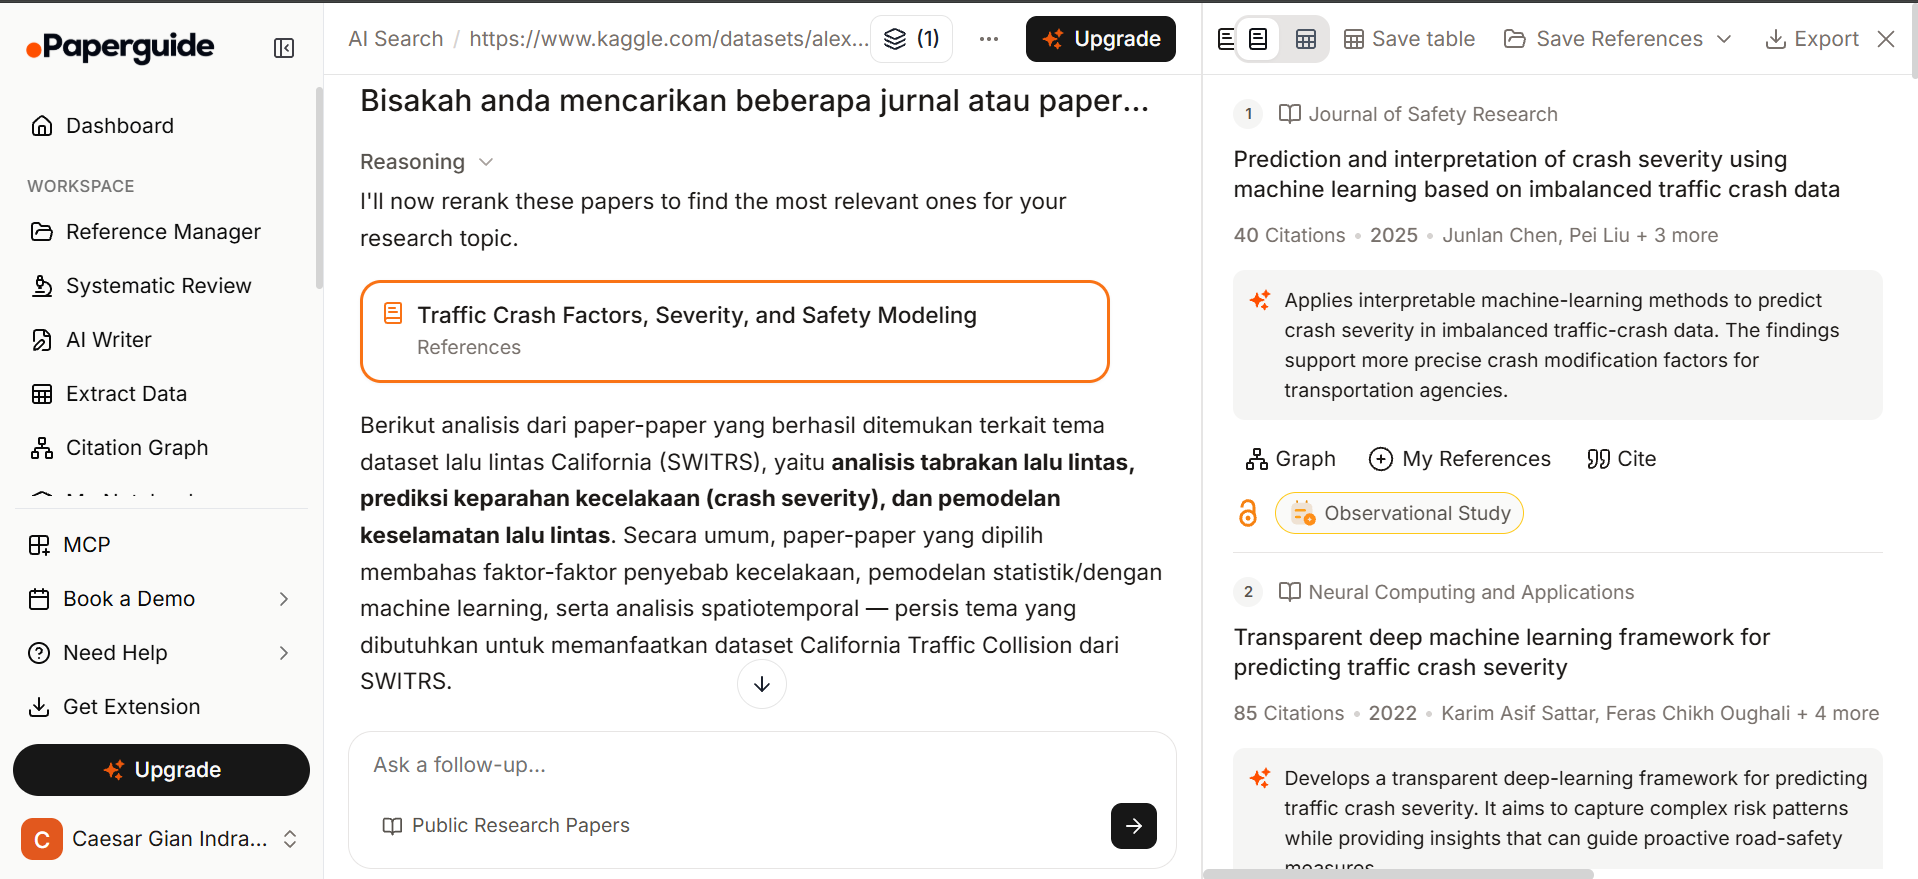

**Gemini**

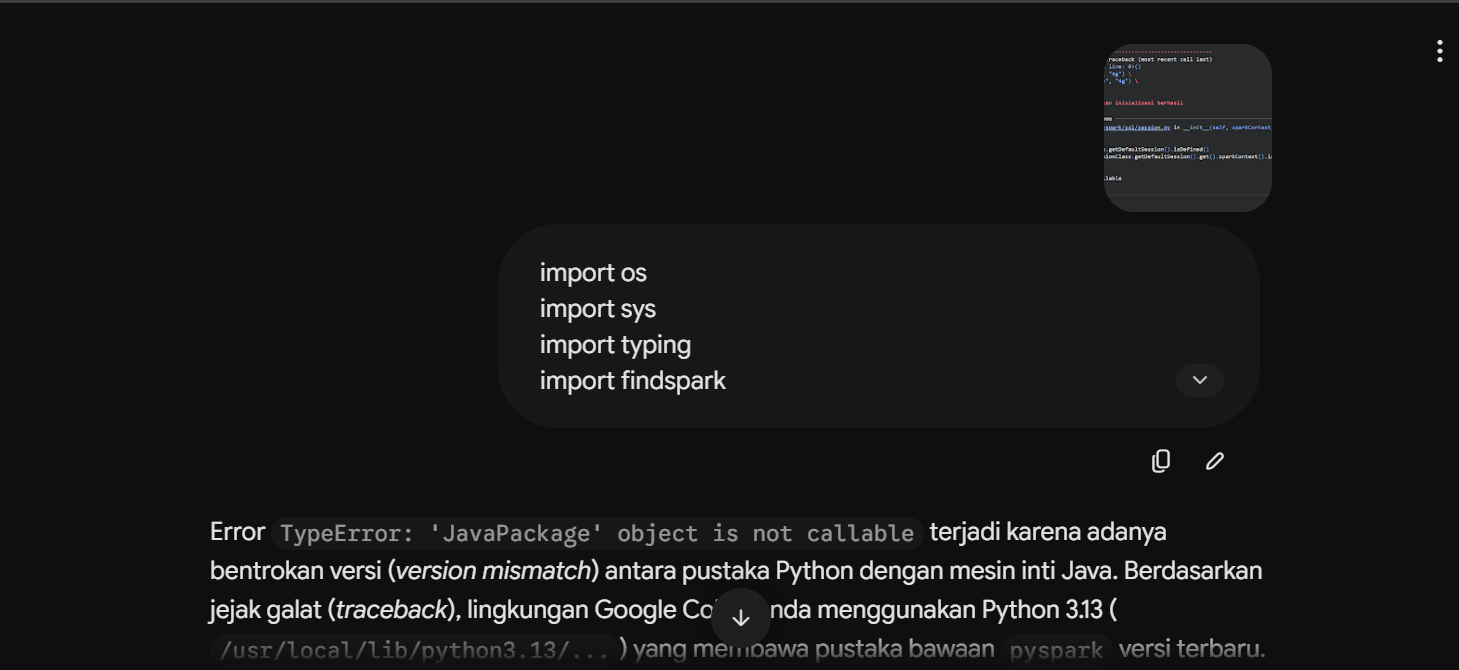

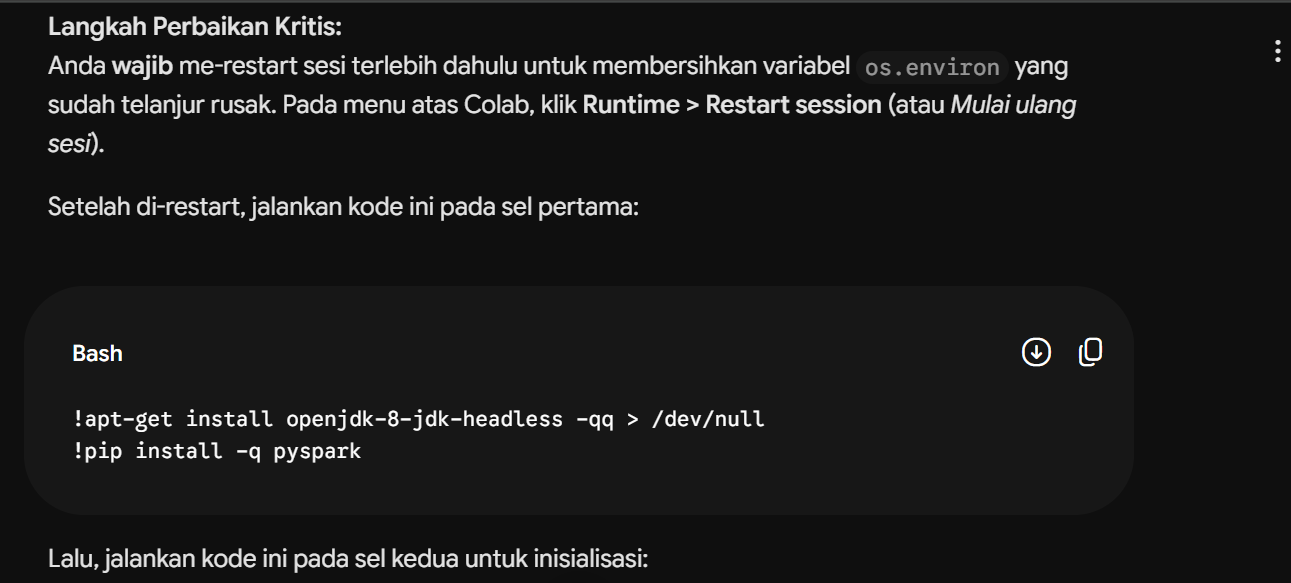

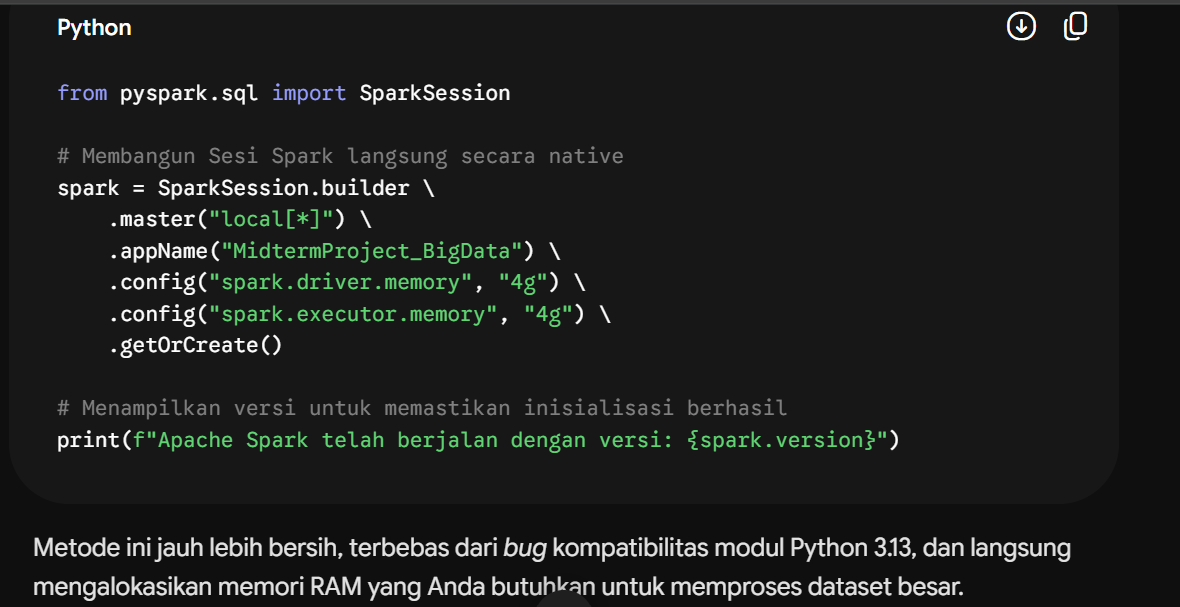

#Versi Python dan Pyspark

In [ ]:
import sys, pandas, matplotlib, seaborn, pyspark, kagglehub
print("Python    :", sys.version)
print("PySpark   :", pyspark.__version__)
print("pandas    :", pandas.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn   :", seaborn.__version__)
print("kagglehub :", kagglehub.__version__)
!java -version

Python    : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PySpark   : 4.0.4
pandas    : 2.2.3
matplotlib: 3.10.0
seaborn   : 0.13.2
kagglehub : 1.0.3
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


#Referensi



1.   Dataset: [California Traffic Collision Data from SWITRS](https://www.kaggle.com/datasets/alexgude/california-traffic-collision-data-from-switrs)
2.   [Predicting Traffic Accident Severity Using Machine Learning Techniques](https://dergipark.org.tr/en/pub/tdfd/article/1136432)
3.   [Analyzing Autonomous Vehicle Collision Types to Support Sustainable Transportation Systems: A Machine Learning and Association Rules Approach](https://www.mdpi.com/2071-1050/16/22/9893)
4.   [Comparison of Statistical and Machine-Learning Models on Road Traffic Accident Severity Classification](https://www.mdpi.com/2073-431X/11/5/80)

